Importing Librarirs

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_style("whitegrid")

Load the Dataset

In [6]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Rows: ",df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows:  7043
Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Data Quality Check Summary


In [8]:
quality = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Unique Values" : df.nunique()
})

print("Duplicate rows : ", df.duplicated().sum())
quality

Duplicate rows :  0


,Data Type,Missing Values,Unique Values
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


Double Check Total Charges

In [9]:
blank_rows = df[df["TotalCharges"].str.strip() == ""]

print("Rows with blank TotalCharges: ", len(blank_rows))
blank_rows[["customerID", "tenure","MonthlyCharges","TotalCharges","Churn"]]

Rows with blank TotalCharges:  11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [10]:
df["TotalCharges"].dtype

dtype('O')

VERIFY TOTAL CHARGES

In [11]:
print("Data type:", df["TotalCharges"].dtype)
print("Missing values: ", df["TotalCharges"].isnull().sum())
print("Rows with TotalCharges = 0:", (df["TotalCharges"]== 0).sum())

df[df["tenure"] == 0][["customerID","tenure","MonthlyCharges","TotalCharges"]]

Data type: object
Missing values:  0
Rows with TotalCharges = 0: 0


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [12]:
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


Standardize Categories

In [13]:
# No phone service/ No internet as NO
service_columns = ["MultipleLines", "OnlineSecurity","OnlineBackup", "DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]

for col in service_columns:
  df[col] = df[col].replace({"No phone service": "No", "No internet service": "No"})


#SeniorCitizen as 0/1 insted of yes or no

df["SeniorCitizen"] = df["SeniorCitizen"].replace({1: "Yes", 0: "No"})

for col in service_columns + ["SeniorCitizen"]:
  print(f"{col:18} -> {df[col].unique()}")

MultipleLines      -> ['No' 'Yes']
OnlineSecurity     -> ['No' 'Yes']
OnlineBackup       -> ['Yes' 'No']
DeviceProtection   -> ['No' 'Yes']
TechSupport        -> ['No' 'Yes']
StreamingTV        -> ['No' 'Yes']
StreamingMovies    -> ['No' 'Yes']
SeniorCitizen      -> ['No' 'Yes']


CHURN FLAG AND OVERALL CHURN RATE

In [14]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print(df["Churn"].value_counts())
print(f"\nOverall churn rate: {df['ChurnFlag'].mean() * 100:.1f}%")

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Overall churn rate: 26.5%


In [15]:
print("Shape: ", df.shape)
print("Missing values: ", df.isnull().sum().sum())
print("Duplicate rows: ", df.duplicated().sum())

df.to_csv("Telco_Churn_Cleaned.csv", index=False)
print("Cleaned file save")

Shape:  (7043, 22)
Missing values:  0
Duplicate rows:  0
Cleaned file save


In [16]:
from google.colab import files
files.download('Telco_Churn_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Analysis part
1) Who is leaving?

In [17]:
def churn_by(column):
  result = df.groupby(column)["ChurnFlag"].agg(["mean","count"])
  result["mean"] = (result["mean"]* 100).round(1)
  result.columns = ["Churn Rate %", "Customers"]
  return result.sort_values("Churn Rate %", ascending=False)

Chun by key Segments

In [18]:
for col in ["Contract","InternetService","PaymentMethod"]:
  print(f"\n---Churn by {col}---")
  print(churn_by(col))



---Churn by Contract---
                Churn Rate %  Customers
Contract                               
Month-to-month          42.7       3875
One year                11.3       1473
Two year                 2.8       1695

---Churn by InternetService---
                 Churn Rate %  Customers
InternetService                         
Fiber optic              41.9       3096
DSL                      19.0       2421
No                        7.4       1526

---Churn by PaymentMethod---
                           Churn Rate %  Customers
PaymentMethod                                     
Electronic check                   45.3       2365
Mailed check                       19.1       1612
Bank transfer (automatic)          16.7       1544
Credit card (automatic)            15.2       1522


Ranking the churn Drivers


In [19]:
columns = ["Contract","InternetService","PaymentMethod","PaperlessBilling","SeniorCitizen","Partner","Dependents","TechSupport","OnlineSecurity","gender"]

gaps = {}
for col in columns:
  rates = df.groupby(col)["ChurnFlag"].mean() *100
  gaps[col] = round(rates.max() - rates.min(),1)

pd.Series(gaps).sort_values(ascending=False).rename("Chun gap (percentage points)")

,Chun gap (percentage points)
Contract,39.9
InternetService,34.5
PaymentMethod,30.0
SeniorCitizen,18.1
PaperlessBilling,17.2
OnlineSecurity,16.7
TechSupport,16.0
Dependents,15.8
Partner,13.3
gender,0.8


Churn by Tenure

In [20]:
#Group the customers who have long journey with the company
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1,12,24,48,72], labels=["0-12 months","13-24 months","25-48 months","49-72 months"]).astype(str)

churn_by("TenureGroup")

,Churn Rate %,Customers
TenureGroup,,
0-12 months,47.4,2186
13-24 months,28.7,1024
25-48 months,20.4,1594
49-72 months,9.5,2239


How much money being lost

In [21]:
churned = df[df["Churn"]== "Yes"]
retained = df[df["Churn"] == "No"]

lost = churned["MonthlyCharges"].sum()
total = df["MonthlyCharges"].sum()

print(f"Monthly revenue lost to churn: {lost:,.0f}")
print(f"Share of total monthly revenue: {lost / total * 100:.1f}%")
print(f"Average monthly bill, churned customers:  {churned['MonthlyCharges'].mean():.2f}")
print(f"Average monthly bill, retained customers: {retained['MonthlyCharges'].mean():.2f}")

Monthly revenue lost to churn: 139,131
Share of total monthly revenue: 30.5%
Average monthly bill, churned customers:  74.44
Average monthly bill, retained customers: 61.27


Charts of key findings

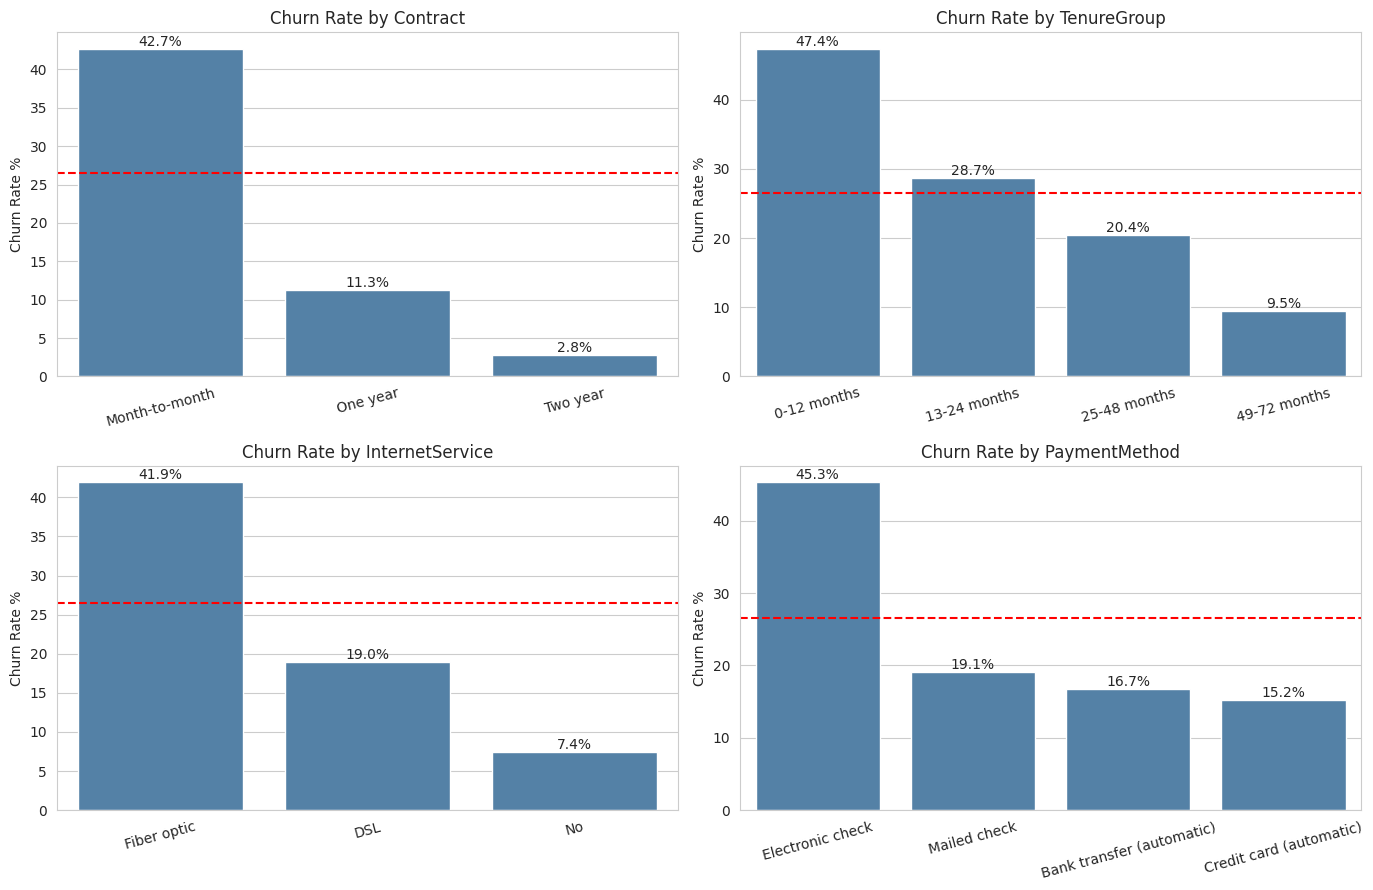

In [22]:
overall = df["ChurnFlag"].mean() * 100
fig, axes = plt.subplots(2,2,figsize=(14,9))

for ax, col in zip(axes.flatten(), ["Contract", "TenureGroup", "InternetService", "PaymentMethod"]):
  data = churn_by(col)
  sns.barplot(x=data.index, y=data["Churn Rate %"], ax=ax, color="steelblue")
  ax.bar_label(ax.containers[0], fmt="%.1f%%")                   # show value on each bar
  ax.axhline(overall, color="red", linestyle="--")               # red line = overall churn
  ax.set_title(f"Churn Rate by {col}")
  ax.set_xlabel("")
  ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


High risk customer

In [23]:
high_risk = df[(df["Contract"] == "Month-to-month") &
               (df["tenure"] <= 12) &
               (df["InternetService"] == "Fiber optic")]
print(f"Customers in this profile: {len(high_risk)}")
print(f"Churn rate: {high_risk['ChurnFlag'].mean() * 100:.1f}%  (overall: {overall:.1f}%)")


Customers in this profile: 916
Churn rate: 70.2%  (overall: 26.5%)


In [31]:
df["TotalCharges"].dtype

dtype('float64')

In [32]:
df["TotalCharges"] = (
    df["TotalCharges"]
    .astype(str)
    .str.strip()
    .replace("", "0")
    .astype(float)
)
print("Data type now:", df["TotalCharges"].dtype)

Data type now: float64


# ML MODEL
Prepare the data

In [35]:
from sklearn.model_selection import train_test_split

y = df["ChurnFlag"]
X= df.drop(columns=["customerID","Churn","ChurnFlag","TenureGroup"])

X= pd.get_dummies(X,drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

print("Number of features:", X.shape[1])
print("Training customers:", len(X_train), "| Test Customers:", len(X_test))
print("Churn rate in training:", round(y_train.mean() * 100,1), "%")
print("Churn rate in test: ",   round(y_test.mean() * 100,1),"%")

Number of features: 23
Training customers: 5634 | Test Customers: 1409
Churn rate in training: 26.5 %
Churn rate in test:  26.5 %


# Train a Simple Model (Logisic Regression)

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create an empty model, then teach it using the training customers
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

# Ask the model to predict for the test customers (people it has never seen)
y_pred = model.predict(X_test)

# Compare its predictions with what really happened
print("Model accuracy:", round(accuracy_score(y_test, y_pred) * 100, 1), "%")
print("Baseline (always guess 'stays'):", round((1 - y_test.mean()) * 100, 1), "%")
print()
print(classification_report(y_test, y_pred, target_names=["Stayed", "Left"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Model accuracy: 80.5 %
Baseline (always guess 'stays'): 73.5 %

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
        Left       0.66      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409

Confusion matrix:
[[926 109]
 [166 208]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# SCALE THE FEATURES, THEN RETRAIN

In [34]:

from sklearn.preprocessing import StandardScaler

# Put all features on the same scale so no single column dominates
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn the scale from training data only
X_test_scaled = scaler.transform(X_test)         # apply the same scale to the test data

# Train again, this time on the scaled data
model = LogisticRegression(max_iter=2000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print("Model accuracy:", round(accuracy_score(y_test, y_pred) * 100, 1), "%")
print()
print(classification_report(y_test, y_pred, target_names=["Stayed", "Left"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Model accuracy: 80.7 %

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
        Left       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion matrix:
[[926 109]
 [163 211]]


#  CATCH MORE CHURNERS (class_weight="balanced")

In [36]:

from sklearn.metrics import recall_score, precision_score

# A small helper so every model prints the same short summary
def evaluate(name, y_true, y_pred):
    print(f"--- {name} ---")
    print("Accuracy        :", round(accuracy_score(y_true, y_pred) * 100, 1), "%")
    print("Recall (Left)   :", round(recall_score(y_true, y_pred) * 100, 1), "%")
    print("Precision (Left):", round(precision_score(y_true, y_pred) * 100, 1), "%")
    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred))
    print()

# Model 1: the scaled model from before (y_pred still holds its predictions)
evaluate("Logistic Regression (first)", y_test, y_pred)

# Model 2: same model, but mistakes on churners count almost 3 times as much
model_balanced = LogisticRegression(max_iter=2000, class_weight="balanced")
model_balanced.fit(X_train_scaled, y_train)
y_pred_balanced = model_balanced.predict(X_test_scaled)

evaluate("Logistic Regression (balanced)", y_test, y_pred_balanced)

--- Logistic Regression (first) ---
Accuracy        : 80.7 %
Recall (Left)   : 56.4 %
Precision (Left): 65.9 %
Confusion matrix:
[[926 109]
 [163 211]]

--- Logistic Regression (balanced) ---
Accuracy        : 73.9 %
Recall (Left)   : 78.1 %
Precision (Left): 50.5 %
Confusion matrix:
[[749 286]
 [ 82 292]]



#   TRY A RANDOM FOREST ---------

In [37]:

from sklearn.ensemble import RandomForestClassifier

# A random forest = many decision trees that vote together
# It does not need scaled data, so we use the original X_train / X_test
forest = RandomForestClassifier(n_estimators=200,        # number of trees
                                min_samples_leaf=5,      # stops trees from memorizing single customers
                                class_weight="balanced", # same idea as before: churners count more
                                random_state=42)         # same result every time
forest.fit(X_train, y_train)
y_pred_forest = forest.predict(X_test)

evaluate("Random Forest (balanced)", y_test, y_pred_forest)

--- Random Forest (balanced) ---
Accuracy        : 77.2 %
Recall (Left)   : 72.5 %
Precision (Left): 55.4 %
Confusion matrix:
[[817 218]
 [103 271]]



 # COMPARE THE MODELS

In [38]:
from sklearn.ensemble import RandomForestClassifier

# A random forest = many decision trees that vote together
# It does not need scaled data, so we use the original X_train / X_test
forest = RandomForestClassifier(n_estimators=200,        # number of trees
                                min_samples_leaf=5,      # stops trees from memorizing single customers
                                class_weight="balanced", # same idea as before: churners count more
                                random_state=42)         # same result every time
forest.fit(X_train, y_train)
y_pred_forest = forest.predict(X_test)

evaluate("Random Forest (balanced)", y_test, y_pred_forest)

--- Random Forest (balanced) ---
Accuracy        : 77.2 %
Recall (Left)   : 72.5 %
Precision (Left): 55.4 %
Confusion matrix:
[[817 218]
 [103 271]]



# COMPARE ALL MODELS FAIRLY

In [39]:

from sklearn.metrics import roc_auc_score

# For each model: its yes/no predictions, and its risk scores (probability of leaving)
models = {
    "Logistic (first)":         (y_pred,          model.predict_proba(X_test_scaled)[:, 1]),
    "Logistic (balanced)":      (y_pred_balanced, model_balanced.predict_proba(X_test_scaled)[:, 1]),
    "Random Forest (balanced)": (y_pred_forest,   forest.predict_proba(X_test)[:, 1]),
}

# Build one summary row per model
rows = []
for name, (pred, prob) in models.items():
    rows.append({
        "Model": name,
        "Accuracy %":  round(accuracy_score(y_test, pred) * 100, 1),
        "Recall %":    round(recall_score(y_test, pred) * 100, 1),
        "Precision %": round(precision_score(y_test, pred) * 100, 1),
        "AUC":         round(roc_auc_score(y_test, prob), 3),
    })

pd.DataFrame(rows).set_index("Model")

,Accuracy %,Recall %,Precision %,AUC
Model,,,,
Logistic (first),80.7,56.4,65.9,0.842
Logistic (balanced),73.9,78.1,50.5,0.841
Random Forest (balanced),77.2,72.5,55.4,0.844


# WHAT DRIVES CHURN?

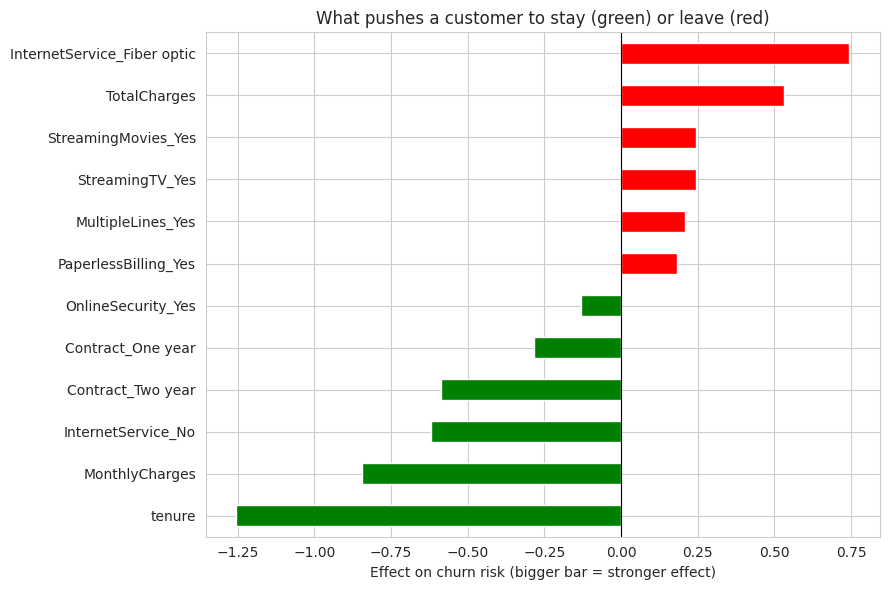

tenure                        -1.25
MonthlyCharges                -0.84
InternetService_No            -0.62
Contract_Two year             -0.59
Contract_One year             -0.28
OnlineSecurity_Yes            -0.13
PaperlessBilling_Yes           0.18
MultipleLines_Yes              0.21
StreamingTV_Yes                0.24
StreamingMovies_Yes            0.24
TotalCharges                   0.53
InternetService_Fiber optic    0.74
dtype: float64


In [41]:

drivers = pd.Series(model.coef_[0], index=X.columns).sort_values()

# Take the 6 strongest pushes towards staying and the 6 strongest towards leaving
strongest = pd.concat([drivers.head(6), drivers.tail(6)])

# Chart: green bars lower the risk, red bars raise it
colors = ["green" if value < 0 else "red" for value in strongest]
strongest.plot(kind="barh", color=colors, figsize=(9, 6))

plt.title("What pushes a customer to stay (green) or leave (red)")
plt.xlabel("Effect on churn risk (bigger bar = stronger effect)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

print(strongest.round(2))

# GIVE EVERY CUSTOMER A RISK SCORE

In [42]:

# Scale all customers with the same scaler, then ask the model for each one's chance of leaving
all_scaled = scaler.transform(X)
df["ChurnRisk"] = model.predict_proba(all_scaled)[:, 1]

# Turn the score into 3 simple groups the retention team can use
df["RiskLevel"] = pd.cut(df["ChurnRisk"], bins=[0, 0.3, 0.6, 1.0],
                         labels=["Low", "Medium", "High"],
                         include_lowest=True).astype(str)

# Check: how many customers are in each group, and what share of them REALLY left?
churn_by("RiskLevel")

,Churn Rate %,Customers
RiskLevel,,
High,71.8,1042
Medium,42.4,1631
Low,9.8,4370


# people who are still with the company but have the highest risk scores.

In [43]:
call_list = (df[df["ChurnFlag"] == 0]
             .sort_values("ChurnRisk", ascending=False)
             [["customerID", "tenure", "Contract", "InternetService", "MonthlyCharges", "ChurnRisk"]]
             .head(10))

call_list

,customerID,tenure,Contract,InternetService,MonthlyCharges,ChurnRisk
3159,5150-ITWWB,3,Month-to-month,Fiber optic,94.85,0.847141
3346,2545-EBUPK,2,Month-to-month,Fiber optic,84.05,0.818622
935,6630-UJZMY,4,Month-to-month,Fiber optic,83.25,0.813970
4039,8161-QYMTT,7,Month-to-month,Fiber optic,94.10,0.813044
5474,4912-PIGUY,1,Month-to-month,Fiber optic,84.60,0.798138
3735,3489-HHPFY,2,Month-to-month,Fiber optic,84.05,0.797521
345,0021-IKXGC,1,Month-to-month,Fiber optic,72.10,0.796502
5213,7668-XCFYV,17,Month-to-month,Fiber optic,92.55,0.795396
4618,6350-XFYGW,4,Month-to-month,Fiber optic,94.75,0.795393
5019,3320-VEOYC,14,Month-to-month,Fiber optic,95.60,0.793831


In [44]:
# ---------- ML STEP 10: SAVE THE SCORED CUSTOMERS FOR POWER BI ----------
df["ChurnRisk"] = df["ChurnRisk"].round(3)        # 3 decimals is plenty

df.to_csv("Telco_Churn_Scored.csv", index=False)

print("Saved:", df.shape[0], "customers,", df.shape[1], "columns")
print(df["RiskLevel"].value_counts())

# Colab files disappear when the session ends, so download a copy to your laptop
from google.colab import files
files.download("Telco_Churn_Scored.csv")

Saved: 7043 customers, 25 columns
RiskLevel
Low       4370
Medium    1631
High      1042
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>